In [1]:
import nivapy3 as nivapy
import pandas as pd
import numpy as np
import os
import matplotlib.pyplot as plt
import warnings
import seaborn as sns
import math

warnings.simplefilter("ignore")

# Vannmiljø water chem data: concatenate & select
This notebook:
1. Concatenates site metadata for sites with data
2. Concatenates water chemistry data extracted from Vannmiljø across vassdragsområder
3. Select data of interest by dropping certain monitoring programmes, parameters, sample media and waterbody types
4. Remove duplicates
5. Add metadata from site metadata sheet to main water chemistry data table, so all is in one single table
6. Unstack from long to wide format (one col per chem variable)
7. Export to csv

The output is a single csv with wide format. A small amount of data cleaning is done (e.g. remove wrong dates), but no cleaning is done of the water chemistry data. That should be done in subsequent steps.

## User input

In [2]:
# Export date (for reading & writing file names)
export_date = "2026-03"

# Folder where raw data are stored
raw_data_dir = r"/home/jovyan/shared/common/norsink/waterchem/vannmiljo/raw_download"

# Folder to store concatenated & tidied data
out_dir = r"/home/jovyan/shared/common/norsink/waterchem/vannmiljo/intermediate"

# Data directory on GitHub (contains e.g. param list)
local_data_dir = r"../../../../data/water_chem"

## Metadata: read & concatenate

Convert coordiantes (utm to lat/lon) and save.

In [3]:
# Read raw metadata files & concatenate
stn_df_vassoms = pd.read_csv(os.path.join(raw_data_dir, f"wc_metadata_{export_date}.csv"))
stn_df_missing_vassons = pd.read_csv(os.path.join(raw_data_dir, f"wc_metadata_missing_vass_{export_date}.csv"))

stn_df = pd.concat([stn_df_vassoms, stn_df_missing_vassons])

# Convert utm to lat, lon
stn_df['utm_zone'] = 33
stn_df = nivapy.spatial.utm_to_wgs84_dd(stn_df, zone="utm_zone", east="CoordX", north="CoordY")

# Quick QC check
bad_latlon = stn_df[(stn_df['lat'].abs() > 90) | (stn_df['lon'].abs() > 180)]
print("Invalid lat/lon rows:", len(bad_latlon))

# Save as CSV
stn_df.to_csv(os.path.join(out_dir, f"ai_wc_metadata_{export_date}.csv"))

stn_df.info()

Invalid lat/lon rows: 0
<class 'pandas.core.frame.DataFrame'>
Index: 110435 entries, 0 to 2970
Data columns (total 18 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   WaterLocationID    110435 non-null  int64  
 1   WaterLocationCode  110435 non-null  object 
 2   CoordX             110435 non-null  float64
 3   CoordY             110435 non-null  float64
 4   WaterCategory      110433 non-null  object 
 5   Name               110095 non-null  object 
 6   WaterBodyID        69173 non-null   object 
 7   WaterBody          68759 non-null   object 
 8   Elevation          103793 non-null  float64
 9   FeatureType        110435 non-null  object 
 10  Fylke              110435 non-null  object 
 11  Kommune            110435 non-null  object 
 12  Vassdragsomrade    110435 non-null  object 
 13  Vannomrade         110419 non-null  object 
 14  Vannregion         110417 non-null  object 
 15  utm_zone           110435 non-null

In [4]:
stn_df

,WaterLocationID,WaterLocationCode,CoordX,CoordY,WaterCategory,Name,WaterBodyID,WaterBody,Elevation,FeatureType,Fylke,Kommune,Vassdragsomrade,Vannomrade,Vannregion,utm_zone,lat,lon
0,27481,01.20-27481,142615.779100,6.499630e+06,C,Skibvigen (10),0120030201-2-C,Tromøysundet,0.0,point,Agder,Arendal,Vegårsvassdraget og Gjerstadvassdraget/kyst Kr...,Nidelva,Agder,33,58.490238,8.864492
1,27482,01.20-27482,140686.054100,6.498295e+06,C,"Tromøysund 3, Trollenes",0120030201-2-C,Tromøysundet,0.0,point,Agder,Arendal,Vegårsvassdraget og Gjerstadvassdraget/kyst Kr...,Nidelva,Agder,33,58.476730,8.833681
2,27499,012-27499,255052.168500,6.702456e+06,L,Jarenvatnet,012-557-L,Jarenvatnet,200.0,point,Innlandet,Gran,Drammensvassdraget/Drammensfjorden vest,Randsfjorden,Vest-Viken,33,60.384103,10.554609
3,27564,01.01-27564,270673.495300,6.562393e+06,C,"Singlefjorden/Hvalerbassenget, Møkkalassene no...",0101010405-C,Østerelva,0.0,point,Østfold,Fredrikstad,Glommavassdraget/Hvaler og Singlefjorden,Glomma sør for Øyeren,Glomma,33,59.138742,10.990717
4,27681,012-27681,151506.328100,6.796696e+06,L,Vangsmjøse,012-517-L,Vangsmjøsi,466.0,point,Innlandet,Vang,Drammensvassdraget/Drammensfjorden vest,Valdres,Vest-Viken,33,61.149188,8.518870
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2966,37614,015-37614,189584.350100,6.612533e+06,L,Bufinntjørn,NaN,NaN,666.0,polygon,Telemark,Notodden,Numedalslågen og Siljanvassdraget/kyst Sandefj...,Numedalslågen,Vest-Viken,33,59.535593,9.507415
2967,39118,015-39118,196965.876667,6.608534e+06,L,Stulstjern,NaN,NaN,602.0,polygon,Buskerud,Kongsberg,Numedalslågen og Siljanvassdraget/kyst Sandefj...,Siljan - Farrisvassdraget,Vest-Viken,33,59.505243,9.643044
2968,113181,01.01-113181,227644.893000,6.563886e+06,C,Stasjon 4b Kilen brygge,0101040200-1-C,Sandefjordsfjorden-indre,0.0,polygon,Vestfold,Sandefjord,Numedalslågen og Siljanvassdraget/kyst Sandefj...,Horten - Larvik,Vest-Viken,33,59.126750,10.239364
2969,58224,015-58224,193503.190000,6.651633e+06,L,Vatnebrynnvatnet,015-379-L,Vatnebrynnvatnet,240.0,polygon,Buskerud,Flesberg,Numedalslågen og Siljanvassdraget/kyst Sandefj...,Numedalslågen,Vest-Viken,33,59.887999,9.519371


## Concatenate water chemistry data

### User input

In [5]:
cols_wc = [
    "WaterLocationID",
    "WaterLocationCode",
    "Name",
    "Contractor",
    "ActivityName",
    "MediumID",
    "ParameterID",
    "SamplingTime",
    "RegValue",
    "Unit",
    "UpperDepth",
    "LowerDepth"
]

converters = {
    'RegValue': pd.to_numeric,
    'UpperDepth': pd.to_numeric,
    'LowerDepth': pd.to_numeric
}

# Filter out any monitoring associated with these activities
activity_name = ["Overvåking av gruvepåvirka vassdrag",
                 "Overvåking av avrenning fra landdeponi"
]

date_index = "SamplingTime"

### Read in parameter list

This same file is used to define the parameters downloaded in the previous notebook.

**NOTE**: Sodium (Na) is auto-parsed as NaN, so have to deal with carefully

In [6]:
# Read in list of params to get
param_list_fpath = os.path.join(local_data_dir, 'vannmiljo_getparams.csv')

# Read in. Need specific NaN handling, as "NA" (Natrium) was being read as NaN
params_df = pd.read_csv(
    param_list_fpath,
    index_col=0,
    keep_default_na=False,   # disable automatic NA detection
    na_values=[]             # ensure nothing is treated as NA unless specified
)

pars_li = params_df.loc[params_df['Get'] == '1'].index.to_list()
pars_li

['N-SNOX',
 'N-TOT',
 'P-TOT',
 'TOC',
 'SIO2',
 'N-NH4',
 'HCO3',
 'P-PO4',
 'PH',
 'CA',
 'CL',
 'DOC',
 'SI-SIO2',
 'NA',
 'N-NO3',
 'P-ORTO',
 'POC',
 'TIC',
 'P-TDP',
 'DIC']

### Concatenate data over vassdragsområder

In [7]:
all_data = pd.DataFrame()

for filename in os.listdir(raw_data_dir):
    if filename.endswith(f"_data_export-{export_date}.csv"):
        file_path = os.path.join(raw_data_dir, filename)
        df = pd.read_csv(
            file_path,
            dtype={"ParameterID": "string"},
            keep_default_na=False,  # Disable default NA set (which includes "NA" - sodium)
            na_values=["", " "],
            converters=converters,
        )

        # Select columns of interest and sort
        df = df[cols_wc].sort_values(["ParameterID", "SamplingTime"]).reset_index(drop=True)

        all_data = pd.concat([all_data, df], ignore_index=True)

all_data.head()

,WaterLocationID,WaterLocationCode,Name,Contractor,ActivityName,MediumID,ParameterID,SamplingTime,RegValue,Unit,UpperDepth,LowerDepth
0,44892,164-44892,"Langvatnet, utløp Hellarmo",NIVA,Overvåking av gruvepåvirka vassdrag,VF,CA,1973-03-27T00:00:00,6.20,mg/l,0.0,0.0
1,44892,164-44892,"Langvatnet, utløp Hellarmo",NIVA,Overvåking av gruvepåvirka vassdrag,VF,CA,1973-04-24T00:00:00,5.60,mg/l,0.0,0.0
2,44892,164-44892,"Langvatnet, utløp Hellarmo",NIVA,Overvåking av gruvepåvirka vassdrag,VF,CA,1973-05-15T00:00:00,5.90,mg/l,0.0,0.0
3,44892,164-44892,"Langvatnet, utløp Hellarmo",NIVA,Overvåking av gruvepåvirka vassdrag,VF,CA,1973-06-15T00:00:00,5.68,mg/l,0.0,0.0
4,44892,164-44892,"Langvatnet, utløp Hellarmo",NIVA,Overvåking av gruvepåvirka vassdrag,VF,CA,1973-07-13T00:00:00,3.51,mg/l,0.0,0.0


## Select data of interest & remove duplicates
### Select data

**Activity:**
Take fairly conservative approach and only drop activities which are clearly targeted at monitoring heavily contaminated sites. E.g. runoff from landfill and mines.

**Parameters:**
Default here is to keep all parameters that were downloaded from Vannmiljø.

**Category:**

Metadata file has column "WaterCategory", which has values ['L', 'R', 'U', 'C', 'G', 'J', 'S']

From https://vannmiljokoder.miljodirektoratet.no/location, these are:

* L: lakes. In 2026 export, around 11 700 sites
* R: rivers. In 2026 exort, around 15 000 sites
* U: Unclassified. 300 sites. Real mix of locations from quick check in Vannmiljø. Often they have microbial data as well as chem. Some look relevant, but drop for now
* C: Coastal. From a cross-check of a selection of codes in Vannmiljø, looks like these are mostly stream/rivers near outlet to sea. i.e. look very relevant. Some are in lakes, but most not. BUT, some of them are definitely marine/brackish. Without Cl- data (not guaranteed), would be hard to screen these out. Safest to just drop them for now.
* G: Grunnvann.
* J: Terrestrial. Not many sites. Most of them for monitoring the effect of airports. But one or two that look like they shouldn't be excluded.
* S: Not included in the metadata website! But not many sites. Quick cross-check of some of them: small, looks like e.g. drains/ditches draining industrial/urban areas.

For now - select only L and R. But there could be some relevant data in especially C.

Result of filtering (2026 export): ~2.5 million rows

In [21]:
# Filter out sites associated with certain activities (here: monitoring of runoff from mines and landfill)
long_df = all_data[~all_data["ActivityName"].isin(activity_name)].copy()
print("Dropped unwanted activies")

# -----------------------
# Select only parameters of interest (here: all params downloaded data for)
long_df = long_df[long_df["ParameterID"].isin(pars_li)]
print("Dropped unwanted parameters")

# -----------------------
# Select freshwater samples only
mediumid_nans = all_data['MediumID'].isna().sum()
if mediumid_nans > 0:
    print("Warning: There are some NaNs in MediumID; filtered to only VF anyway, but check the data for MediumID = NaN")
else:
    print("Picking only MediumID == 'VF'. Checked for NaNs in MediumID, none found")
long_df = long_df[long_df['MediumID'] == 'VF']

# -----------------------
# Select only river and lake samples

# First need to join additional columns from metadata file to the water chem data.
# NOTE: only need WaterCategory for this step, but add others too for later
selected_meta_cols = stn_df[['WaterLocationCode', 'lon', 'lat', 'WaterCategory']]

# First check for NaNs in the water chem df. Expected in water chem cols, but not in metadata cols.
# Especially in WaterLocationCode, which is used to merge with site metadata info
if long_df['WaterLocationID'].isna().sum() > 0:
    print("WARNING! NaNs in WaterLocationCode in the water chem data. Won't merge before these are sorted.")
else:
    # Merge water chemistry with selected metadata
    long_df = pd.merge(selected_meta_cols, long_df, on='WaterLocationCode')

keep_categories = ['R', 'L']
long_df = long_df[long_df['WaterCategory'].isin(keep_categories)]
print(f"Only keeping Water Category == {keep_categories}")

long_df

Dropped unwanted activies
Dropped unwanted parameters
Picking only MediumID == 'VF'. Checked for NaNs in MediumID, none found
Only keeping Water Category == ['R', 'L']


,WaterLocationCode,lon,lat,WaterCategory,WaterLocationID,Name,Contractor,ActivityName,MediumID,ParameterID,SamplingTime,RegValue,Unit,UpperDepth,LowerDepth
0,012-27499,10.554609,60.384103,L,27499,Jarenvatnet,NIVA,Landsomfattende trofiundersøkelse,VF,CA,1988-08-27T00:00:00,44.00,mg/l,0.0,10.0
1,012-27499,10.554609,60.384103,L,27499,Jarenvatnet,UKJENT,Lokal overvåking av kalka vassdrag,VF,CA,1993-07-01T00:00:00,58.00,mg/l,NaN,NaN
2,012-27499,10.554609,60.384103,L,27499,Jarenvatnet,NIVA,Landsomfattende trofiundersøkelse,VF,CA,1993-09-28T00:00:00,58.00,mg/l,0.0,10.0
3,012-27499,10.554609,60.384103,L,27499,Jarenvatnet,NIVA,Landsomfattende trofiundersøkelse,VF,CA,2000-08-18T00:00:00,53.90,mg/l,0.0,10.0
4,012-27499,10.554609,60.384103,L,27499,Jarenvatnet,NIVA,Landsomfattende trofiundersøkelse,VF,CA,2001-09-05T00:00:00,43.40,mg/l,0.0,10.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2526270,015-39118,9.643044,59.505243,L,39118,Stulstjern,FMVA,Lokal overvåking av kalka vassdrag,VF,PH,2002-10-06T00:00:00,5.95,<ubenevnt>,NaN,NaN
2526271,015-39118,9.643044,59.505243,L,39118,Stulstjern,FMVA,Lokal overvåking av kalka vassdrag,VF,PH,2003-10-01T00:00:00,6.80,<ubenevnt>,NaN,NaN
2526272,015-39118,9.643044,59.505243,L,39118,Stulstjern,FMVA,Lokal overvåking av kalka vassdrag,VF,PH,2005-09-30T00:00:00,7.00,<ubenevnt>,NaN,NaN
2526273,015-39118,9.643044,59.505243,L,39118,Stulstjern,FMVA,Lokal overvåking av kalka vassdrag,VF,SIO2,2003-10-01T00:00:00,1095.66,µg/l Si,NaN,NaN


In [22]:
# # # For exploring the different categories
# cat = 'C'
# cat_df = long_df.loc[long_df['WaterCategory'] == cat]
# len(cat_df['WaterLocationCode'].unique())
# # cat_df.head(10)

### Remove duplicates

There are two kinds of duplicates in the data, which are dealt with differently:
- Identical values in every way -> Drop duplicate
- Identical site/date/param metadata, but different values -> Group and calculate a mean, as there is not enough information in the vannmiljø metadata to choose one value over another. **Note:** No need to do this if only exporting the wide format, as it's redone during the unstacking. So it's optional here.


In [23]:
# First, detect and fix NaNs in metadata columns

# Define metadata columns (everything except RegValue)
metadata_cols = [c for c in long_df.columns if c != "RegValue"]

print("Checking metadata columns for NaNs...\n")

# Count NaNs
na_counts = long_df[metadata_cols].isna().sum().sort_values(ascending=False)
print("NaN counts per metadata column:")
print(na_counts[na_counts > 0])
print("")

# Separate numeric and string metadata columns
numeric_cols = [c for c in metadata_cols if pd.api.types.is_numeric_dtype(long_df[c])]
string_cols  = [c for c in metadata_cols if long_df[c].dtype == "object"]

print(f"Numeric metadata columns: {numeric_cols}")
print(f"String metadata columns:  {string_cols}\n")

# Fill NaNs appropriately
# Numeric metadata → fill with -999 sentinel
for col in numeric_cols:
    if long_df[col].isna().any():
        long_df[col] = long_df[col].fillna(-999)
        print(f"Filled NaNs in numeric metadata column '{col}' with -999")

# String metadata → fill with "Not provided"
for col in string_cols:
    if long_df[col].isna().any():
        long_df[col] = long_df[col].fillna("Not provided")
        print(f"Filled NaNs in string column '{col}' with 'Not provided'")

print("\nRechecking NaNs after filling...")
print(long_df[metadata_cols].isna().sum().sum(), "NaNs remaining\n")

Checking metadata columns for NaNs...

NaN counts per metadata column:
LowerDepth    1019476
UpperDepth    1019476
Contractor     261891
dtype: int64

Numeric metadata columns: ['lon', 'lat', 'WaterLocationID', 'UpperDepth', 'LowerDepth']
String metadata columns:  ['WaterLocationCode', 'WaterCategory', 'Name', 'Contractor', 'ActivityName', 'MediumID', 'SamplingTime', 'Unit']

Filled NaNs in numeric metadata column 'UpperDepth' with -999
Filled NaNs in numeric metadata column 'LowerDepth' with -999
Filled NaNs in string column 'Contractor' with 'Not provided'

Rechecking NaNs after filling...
0 NaNs remaining



In [24]:
# Remove duplicate rows (where all values are identical)
n_rows_start = len(long_df)
print(f"Length of long_df before removing duplicates: {n_rows_start}")

num_full_dups = long_df.duplicated().sum()
if num_full_dups > 0:
    print(f"Removing {num_full_dups} full-row duplicates (exact duplicates).")
long_df = long_df.drop_duplicates()
n_rows_after_full = len(long_df)

print("Rows after full-duplicate removal:", n_rows_after_full)
print("")

# ----------------------------------
# ** Optional ** - remove multiple values for single days/places/metadata in the long format

# Look at how many rows have duplicate metadata values, but different concentrations
num_meta_dups = long_df.duplicated(subset=metadata_cols).sum()

# Count unique metadata groups before averaging
n_unique_metadata_groups = long_df[metadata_cols].drop_duplicates().shape[0]

# Group by the specified columns and calculate the mean (ignoring NaNs)
long_agg_df = long_df.groupby(metadata_cols, as_index=False).agg({"RegValue": "mean"}).reset_index()

print(f"{num_meta_dups} rows have duplicate metadata but may differ in RegValue.")
print("Unique metadata groups:", n_unique_metadata_groups)
print("Rows removed during averaging:", n_rows_after_full - n_unique_metadata_groups)
print(f"Length of long_df after removing duplicates (averaging): {len(long_agg_df)}")
print("")

Length of long_df before removing duplicates: 2493435
Removing 14973 full-row duplicates (exact duplicates).
Rows after full-duplicate removal: 2478462

49873 rows have duplicate metadata but may differ in RegValue.
Unique metadata groups: 2428589
Rows removed during averaging: 49873
Length of long_df after removing duplicates (averaging): 2428589



In [25]:
# dups = long_df[long_df.duplicated(metadata_cols_dups, keep=False)]
# dups_sorted = dups.sort_values(metadata_cols_dups)
# dups_sorted

### Tidy

In [26]:
# -----------------------
# Make new param ID col that includes unit info, unless the parameter is PH
# Old:
# long_df['Param_unit'] = (long_df['ParameterID'] + "_" + long_df['Unit']).str.replace('/', '_').str[:-1].str.strip()

# New: bit more complex to deal with pH and simplify results

# If Unit can contain NaNs, make it robust:
param = long_df['ParameterID']
unit = (
    long_df['Unit']
    .fillna('')
    .str.replace(r'[µμ]', 'u', regex=True)   # replace any micro symbol with simpler 'u'
)

suffixes = r'(?:N|P|C|SiO2|Si)'  # the trailing tokens to remove

long_df['Param_unit'] = np.where(
    param.eq('PH'),
    'PH',  # just "PH"
    (param + "_" + unit)
      .str.replace('/', '_', regex=False)
      .str.replace(rf'\s+{suffixes}$', '', regex=True)  # drop trailing " N", " P", etc.
      .str.strip()                                    # trim any leftover whitespace
)
# -----------------------
# Reformat dates
long_df[date_index] = pd.to_datetime(long_df[date_index], format="%Y-%m-%dT%H:%M:%S", errors="raise").dt.tz_localize(None)

# Dates: assume anything before 1910 is technical error (checked & definitely the case - presumably added without year info)
long_df = long_df.loc[long_df[date_index] > '1910', :]

# -----------------------
# Drop unwanted cols & rename others
long_df = long_df.drop(['MediumID'], axis=1)
long_df = long_df.rename({'SamplingTime': 'Date'}, axis=1)

# Convert from long to wide format

Pivot long to wide. Parameter ID values become columns, cells get RegValue

(If not done above: aggregate to daily mean (where multiple values are present for the same metadata col values)

In [26]:
drop_cols = ['ParameterID', 'Unit']
drop_cols2 = ['ParameterID', 'Unit', 'Param_unit']

metadata_cols_all = [c for c in long_df.columns if c != "RegValue"]
metadata_cols_long = [item for item in metadata_cols_all if item not in drop_cols2]

wc_df = (
    long_df.drop(drop_cols, axis=1)
    .pivot_table(
        index=metadata_cols_long,
        columns="Param_unit",
        values="RegValue",
        aggfunc="mean",          # mean across duplicates
        observed=True            # more efficient for categoricals
    )
    .reset_index()
)

wc_df = wc_df.sort_values(by=['WaterLocationCode', 'Date']).reset_index(drop=True)

# Remove "Param_unit" name of columns axis
wc_df.columns.name = None

# Also make list of data cols for later use
data_cols = [col for col in wc_df.columns if col not in metadata_cols_long]

wc_df

,WaterLocationCode,lon,lat,WaterCategory,WaterLocationID,Name,Contractor,ActivityName,Date,UpperDepth,...,NA_mg_l,P-ORTO_ug_l,P-PO4_ug_l,P-TDP_ug_l,P-TOT_ug_l,PH,POC_ug_l,SI-SIO2_ug_l,SIO2_ug_l,TOC_mg_l
0,001-100811,11.672260,59.344788,L,100811,Husborn friområde,Haldenvassdraget vannområde,Overvåking av badevann,2024-06-24,0.0,...,NaN,NaN,NaN,NaN,NaN,6.8,NaN,NaN,NaN,NaN
1,001-100811,11.672260,59.344788,L,100811,Husborn friområde,Haldenvassdraget vannområde,Overvåking av badevann,2024-07-25,0.0,...,NaN,NaN,NaN,NaN,NaN,7.0,NaN,NaN,NaN,NaN
2,001-100811,11.672260,59.344788,L,100811,Husborn friområde,Haldenvassdraget vannområde,Overvåking av badevann,2025-07-02,0.0,...,NaN,NaN,NaN,NaN,NaN,7.2,NaN,NaN,NaN,NaN
3,001-100812,11.659740,59.377378,L,100812,Ytterbøl senter,Haldenvassdraget vannområde,Overvåking av badevann,2024-06-24,0.0,...,NaN,NaN,NaN,NaN,NaN,6.7,NaN,NaN,NaN,NaN
4,001-100812,11.659740,59.377378,L,100812,Ytterbøl senter,Haldenvassdraget vannområde,Overvåking av badevann,2024-07-25,0.0,...,NaN,NaN,NaN,NaN,NaN,7.0,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
675974,315-48467,11.465823,58.958420,R,48467,"Lille Langvann, utløp",Eurofins Environment Testing Norway (Moss),Lokal overvåking av kalka vassdrag,2024-04-20,0.0,...,5.4,NaN,NaN,NaN,NaN,6.4,NaN,NaN,NaN,NaN
675975,HAV-125308,11.465162,60.115940,R,125308,"05 Gorolund, kum 2999","Prøvetaking: COWI, lab: Eurofins",Tiltaksorientert overvåking,2022-04-07,0.0,...,NaN,47.0,NaN,NaN,73.0,NaN,NaN,NaN,NaN,NaN
675976,HAV-125308,11.465162,60.115940,R,125308,"05 Gorolund, kum 2999","Prøvetaking: COWI, lab: Eurofins",Tiltaksorientert overvåking,2022-05-20,0.0,...,NaN,NaN,NaN,NaN,68.0,NaN,NaN,NaN,NaN,NaN
675977,HAV-125308,11.465162,60.115940,R,125308,"05 Gorolund, kum 2999","Prøvetaking: COWI, lab: Eurofins",Tiltaksorientert overvåking,2022-09-07,0.0,...,NaN,57.0,NaN,NaN,120.0,NaN,NaN,NaN,NaN,8.5


In [27]:
# Check columns present
wc_df.columns

Index(['WaterLocationCode', 'lon', 'lat', 'WaterCategory', 'WaterLocationID',
       'Name', 'Contractor', 'ActivityName', 'Date', 'UpperDepth',
       'LowerDepth', 'CA_mg_l', 'CL_mg_l', 'DOC_mg_l', 'HCO3_mmol_l',
       'N-NH4_ug_l', 'N-NO3_ug_l', 'N-SNOX_ug_l', 'N-TOT_ug_l', 'NA_mg_l',
       'P-ORTO_ug_l', 'P-PO4_ug_l', 'P-TDP_ug_l', 'P-TOT_ug_l', 'PH',
       'POC_ug_l', 'SI-SIO2_ug_l', 'SIO2_ug_l', 'TOC_mg_l'],
      dtype='object')

In [30]:
# Check datetime
wc_df['Date']

0        2024-06-24
1        2024-07-25
2        2025-07-02
3        2024-06-24
4        2024-07-25
            ...    
675974   2024-04-20
675975   2022-04-07
675976   2022-05-20
675977   2022-09-07
675978   2022-12-07
Name: Date, Length: 675979, dtype: datetime64[ns]

# Export

In [31]:
# Save to CSV
wc_df.to_csv(os.path.join(out_dir, f"waterchem_vannmiljo_rivs-lakes_wide_{export_date}.csv"),
             date_format="%Y-%m-%d",
             index=False)

# Basic QC
## Quick plot for Glomma

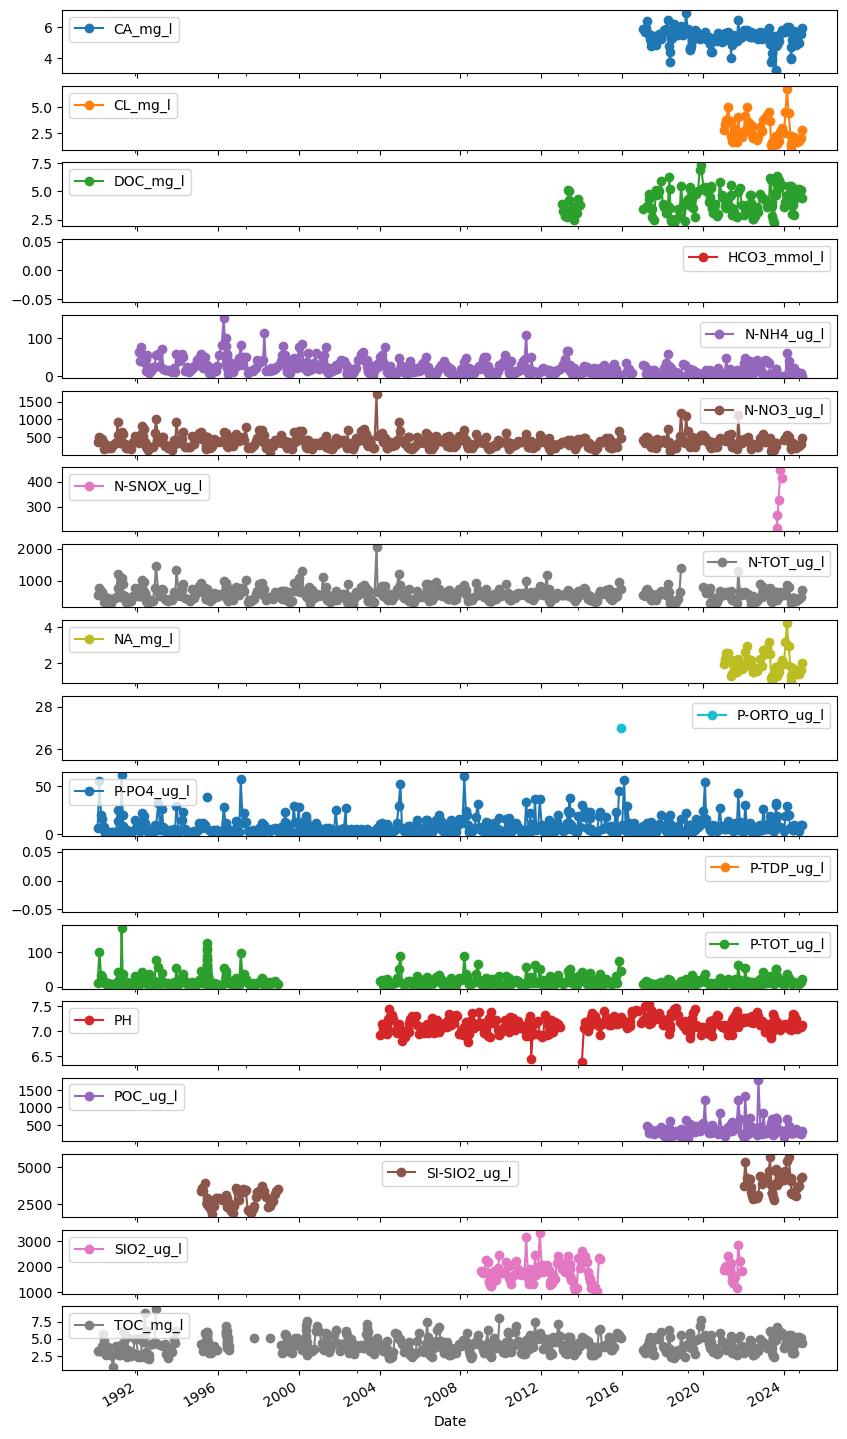

,WaterLocationCode,lon,lat,WaterCategory,WaterLocationID,Name,Contractor,ActivityName,UpperDepth,LowerDepth,...,NA_mg_l,P-ORTO_ug_l,P-PO4_ug_l,P-TDP_ug_l,P-TOT_ug_l,PH,POC_ug_l,SI-SIO2_ug_l,SIO2_ug_l,TOC_mg_l
Date,,,,,,,,,,,,,,,,,,,,,
1990-01-10,002-38516,11.134294,59.279465,R,38516,Glomma ved Sarpsfoss,NIVA,Elvetilførselsprogrammet,0.0,0.0,...,NaN,NaN,6.0,NaN,11.0,NaN,NaN,NaN,NaN,3.27
1990-02-12,002-38516,11.134294,59.279465,R,38516,Glomma ved Sarpsfoss,NIVA,Elvetilførselsprogrammet,0.0,0.0,...,NaN,NaN,55.0,NaN,100.0,NaN,NaN,NaN,NaN,3.27
1990-03-14,002-38516,11.134294,59.279465,R,38516,Glomma ved Sarpsfoss,NIVA,Elvetilførselsprogrammet,0.0,0.0,...,NaN,NaN,20.0,NaN,35.0,NaN,NaN,NaN,NaN,3.27
1990-04-04,002-38516,11.134294,59.279465,R,38516,Glomma ved Sarpsfoss,NIVA,Elvetilførselsprogrammet,0.0,0.0,...,NaN,NaN,16.0,NaN,27.0,NaN,NaN,NaN,NaN,3.88
1990-04-26,002-38516,11.134294,59.279465,R,38516,Glomma ved Sarpsfoss,NIVA,Elvetilførselsprogrammet,0.0,0.0,...,NaN,NaN,5.5,NaN,15.0,NaN,NaN,NaN,NaN,5.64


In [135]:
# Check data for Glomma (WaterLocationID == 38516)
test_df = wc_df.loc[wc_df['WaterLocationID'] == 38516].set_index('Date')

test_df[data_cols].plot(subplots=True, figsize=(10, 20), marker='o')
plt.show()

test_df.head()

## High level snapshot

In [136]:
# Ensure analytes are numeric; identify non-numeric residues (e.g., "<0.5")
non_numeric_cols = []
for c in data_cols:
    if not pd.api.types.is_numeric_dtype(wc_df[c]):
        non_numeric_cols.append(c)
non_numeric_cols

[]

In [137]:
# High level snapshot

# Add year/month for fast temporal summaries
wc_df['Year'] = wc_df['Date'].dt.year
wc_df['Month'] = wc_df['Date'].dt.month

print("Shape:", wc_df.shape)
print("Time span:", wc_df['Date'].min(), "to ", wc_df['Date'].max())
print("# unique locations:", wc_df['WaterLocationCode'].nunique())

counts_by_year = wc_df['Year'].value_counts().sort_index()
print("Counts by year:\n", counts_by_year.head(20))

print("")

Shape: (675979, 31)
Time span: 1928-10-28 00:00:00 to  2026-03-02 00:00:00
# unique locations: 28330
Counts by year:
 Year
1928      1
1941      3
1942     11
1950      3
1952      1
1953     39
1954    102
1958     35
1959     32
1960     13
1961     15
1962     39
1963     63
1964    310
1965    176
1966    109
1967     67
1968    169
1969    282
1970    454
Name: count, dtype: int64



In [80]:
# # Investigate dates pre 1940 - see it's wrong mostly, especially pre 1910.
# early_df = wc_df.loc[wc_df['Date'] < '1940'].dropna(how='all', axis=1)
# early_df

In [82]:
# # Investigate dates in 1954 - looks plausible. All one lake (Gjersjøen), pH and Ca data only
# early_df = wc_df.loc[(wc_df['Date'] > '1953') & (wc_df['Date'] < '1955')].dropna(how='all', axis=1)
# early_df

In [139]:
# Parameter-level quick profile
q_list = [0.5]

def profile_param(s: pd.Series) -> pd.Series:
    s_non = s.dropna()
    out = {
        'n': s_non.size,
        'pct_miss': (1 - s_non.size/len(s)) if len(s) else np.nan,
        'n_zero': int((s_non == 0).sum()),
        'n_neg': int((s_non < 0).sum()),
        'min': s_non.min() if not s_non.empty else np.nan,
        'max': s_non.max() if not s_non.empty else np.nan,
    }
    if not s_non.empty:
        qs = s_non.quantile(q_list)
        for q, v in qs.items():
            out[f'q_{int(q*100)}'] = v
    return pd.Series(out)

for wb in ['R', 'L']:
    print(wb)
    print(len(cur_df))
    cur_df = wc_df.loc[wc_df['WaterCategory'] == wb, :]

    param_profile = pd.DataFrame({c: profile_param(cur_df[c]) for c in data_cols}).T
    param_profile = param_profile.sort_values(by='pct_miss', ascending=False)
    print(param_profile.head(20))
    print("")

R
240293
                     n  pct_miss  n_zero  n_neg      min        max     q_50
P-TDP_ug_l        31.0  0.999929     0.0    0.0    5.000      100.0     8.40
HCO3_mmol_l      993.0  0.997721    17.0    0.0    0.000  1500000.0     0.74
POC_ug_l        3943.0  0.990950    75.0   18.0 -700.000     9100.0   181.00
SIO2_ug_l       8753.0  0.979910     0.0    0.0    2.300    10100.0   699.05
DOC_mg_l       10341.0  0.976265     5.0    0.0    0.000      390.0     3.20
SI-SIO2_ug_l   12853.0  0.970500     0.0    0.0    0.055    47700.0  1827.00
N-SNOX_ug_l    34548.0  0.920705    66.0    0.0    0.000   157000.0   400.00
P-ORTO_ug_l    42309.0  0.902892    93.0    0.0    0.000    18100.0     7.00
NA_mg_l        82775.0  0.810014    55.0    0.0    0.000     9390.0     1.89
CL_mg_l        82824.0  0.809902    13.0    0.0    0.000    27018.0     2.76
P-PO4_ug_l     87285.0  0.799663   144.0    0.0    0.000   158000.0     5.50
N-NH4_ug_l     96261.0  0.779061    45.0    0.0    0.000  1000000.0

## Coverage (nobs per var per year)

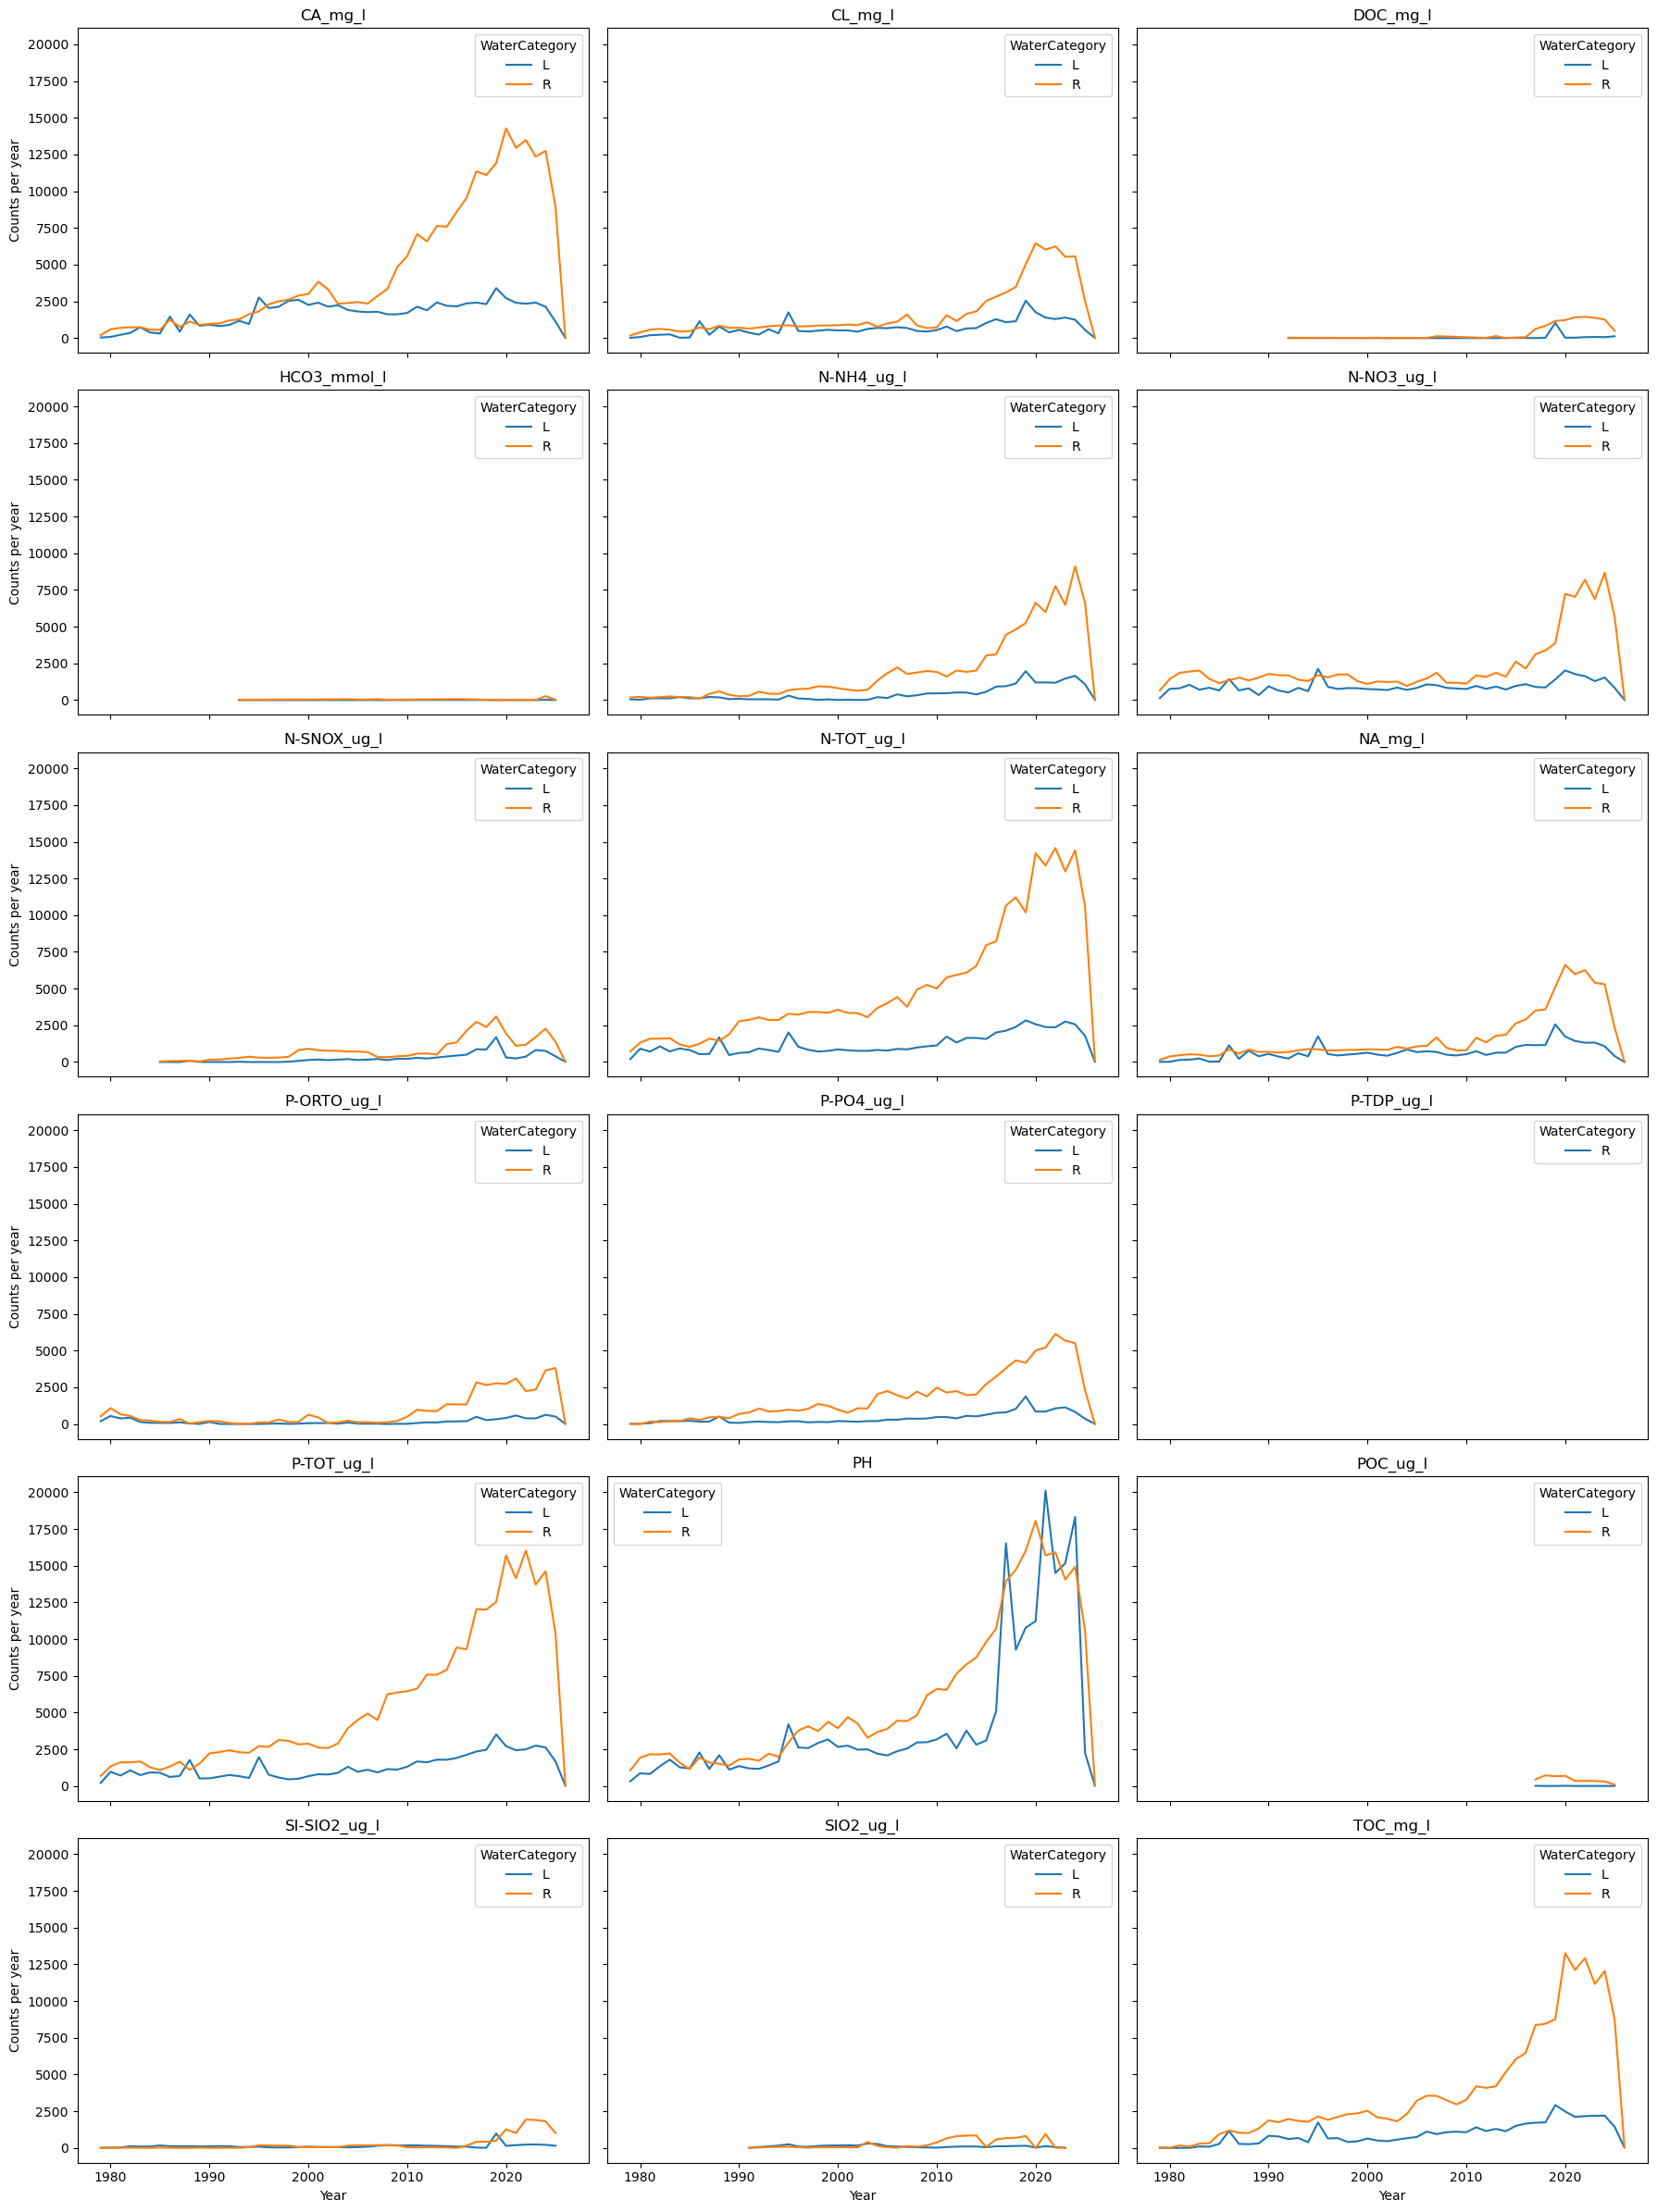

In [144]:
vars_to_plot = data_cols

plot_df = wc_df.loc[wc_df['Date'] > '1979']

nvars = len(vars_to_plot)
ncols = 3
nrows = math.ceil(nvars / ncols)

fig, axes = plt.subplots(
    nrows=nrows,
    ncols=ncols,
    figsize=(6*ncols, 4*nrows),
    sharex=True, sharey=True
)

axes = axes.flatten()

for ax, var in zip(axes, vars_to_plot):

    # Build coverage table: count non-NA values per year × WaterCategory
    df_tmp = plot_df[['Year', 'WaterCategory', var]].copy()
    df_tmp = df_tmp.dropna(subset=[var])

    coverage = pd.crosstab(df_tmp['Year'], df_tmp['WaterCategory'])

    # Plot (line plot like your original)
    coverage.plot(ax=ax)
    ax.set_title(var)
    ax.set_ylabel("Counts per year")
    ax.set_xlabel("Year")
    # ax.set_ylim(bottom=0)

# Hide unused axes if any
for ax in axes[nvars:]:
    ax.axis("off")

plt.tight_layout()
plt.show()

Comments:
* Especially rivers: big increase after around 2000: river monitoring programme really started up. From 2015'ish: referanseelver started up.

## Boxplots per var (lakes vs rivs)

These show that there is lots of data cleaning to be done for most of the variables. E.g. NH4-N concentrations > 1 mg/l are a bit suspect, never mind above 10 (of which there are many of). Leave that for a separate notebook.

**To do: define plausible bounds for each chem variable**. For any values outside those bounds, decide whether to:
- Delete
- There's a systematic units issue that can be corrected (e.g. factor 1000 out)

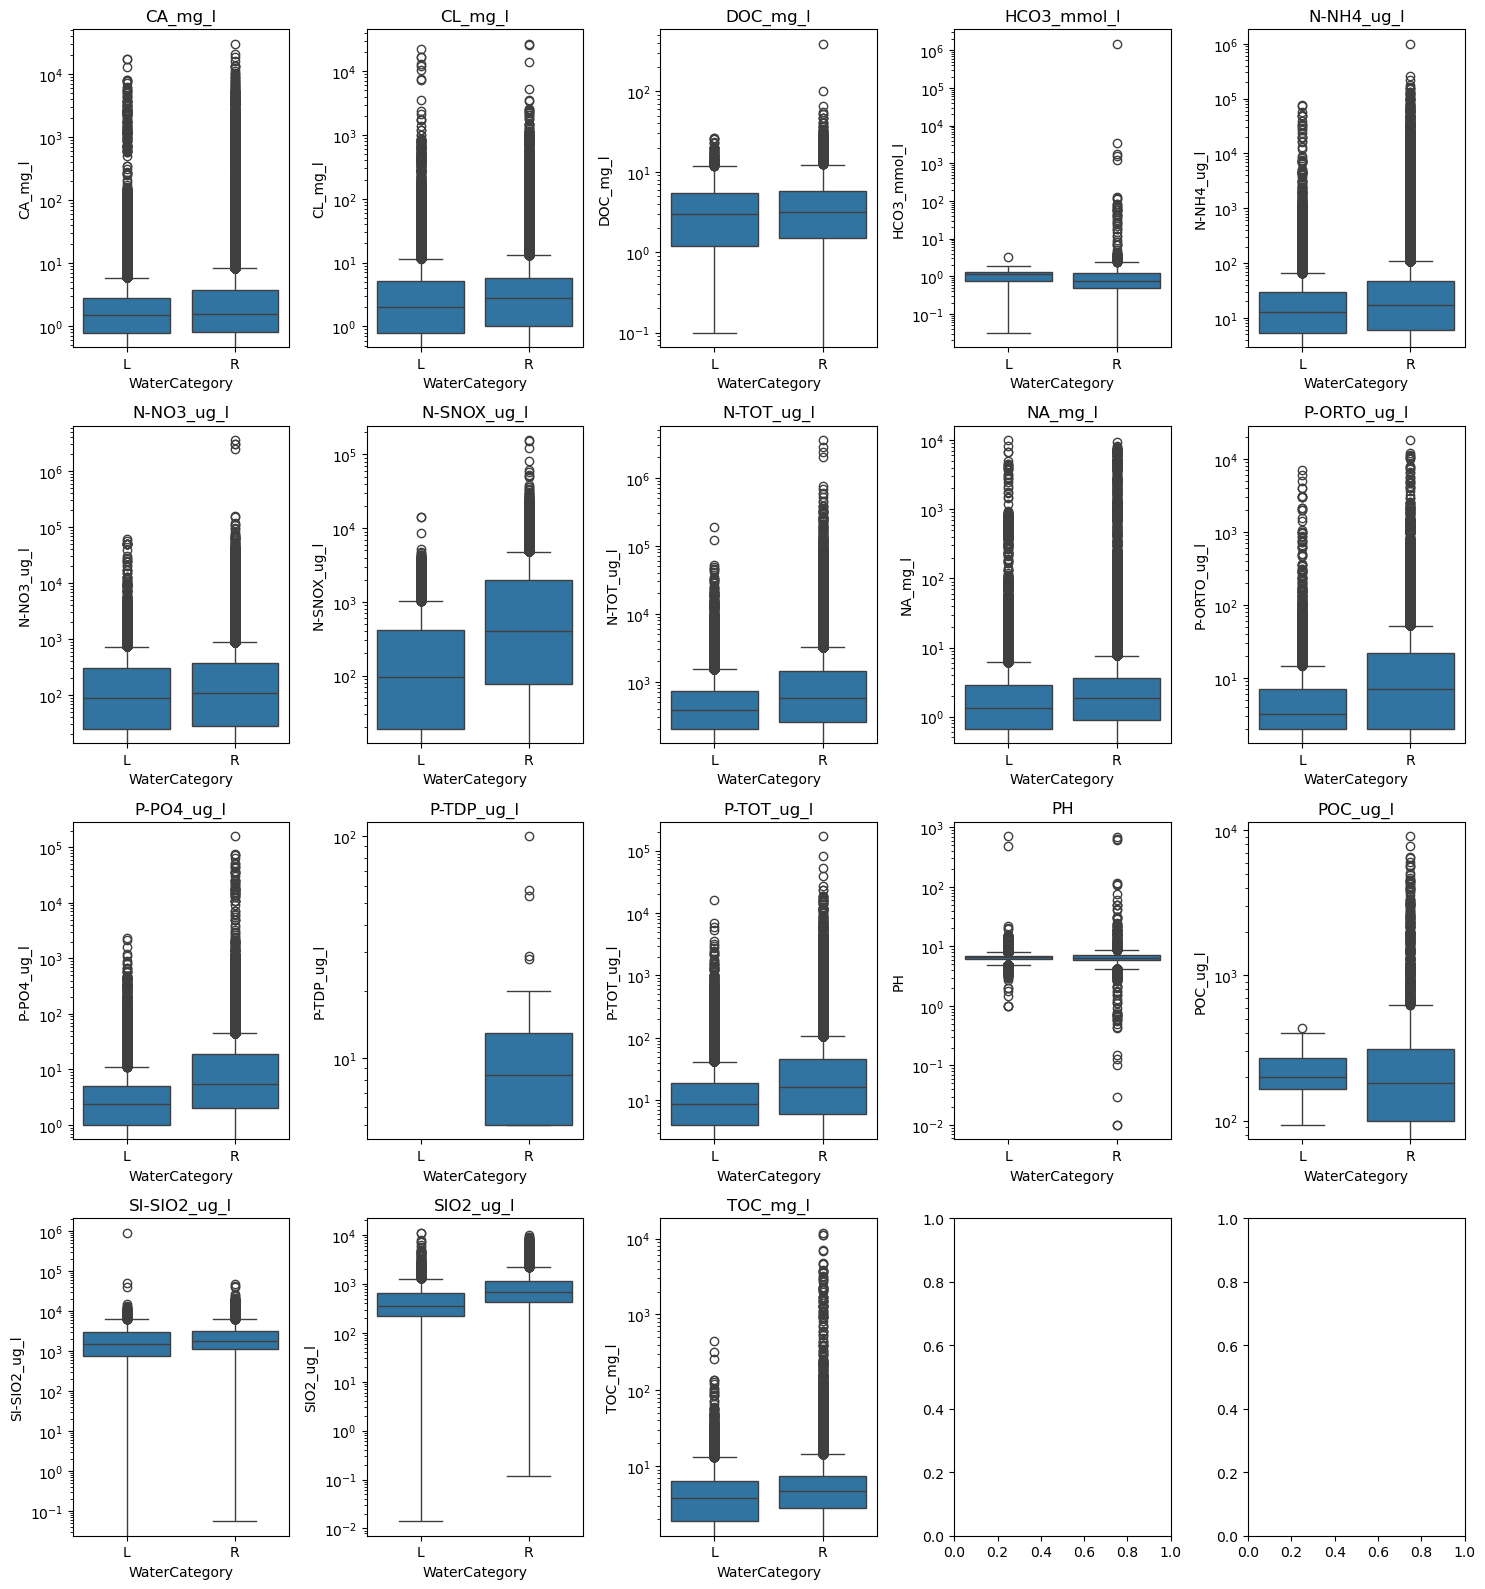

In [122]:
vars_to_plot = data_cols

nvars = len(vars_to_plot)
ncols = 5
nrows = math.ceil(nvars / ncols)

fig, axes = plt.subplots(
    nrows=nrows,
    ncols=ncols,
    figsize=(3*ncols, 4*nrows),
    sharex=False
)

axes = axes.flatten()

for ax, var in zip(axes, vars_to_plot):
    sns.boxplot(
        data=wc_df[[var, 'WaterCategory']],
        y=var,
        x="WaterCategory",
        ax=ax,
        hue=None,
        showfliers=True
    )
    ax.set_yscale("log")
    ax.set_title(var)

# Hide unused axes if any
for ax in axes[nvars:]:
    ax.axis("off")

plt.tight_layout()
plt.show()